In [13]:
# Load the uploaded CSV file for inspection
import pandas as pd

# File path
file_path = 'project_data/Merged_NonMissing_Patient_Data.csv'

# Load the CSV file into a DataFrame
patient_data = pd.read_csv(file_path)

# Display the first few rows of the dataset
patient_data.head(), patient_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   ID            82 non-null     object 
 1   age           82 non-null     int64  
 2   sex           82 non-null     int64  
 3   smoke         82 non-null     int64  
 4   smoke_amount  82 non-null     int64  
 5   height        82 non-null     int64  
 6   weight        82 non-null     int64  
 7   BMI           82 non-null     float64
 8   BSA           82 non-null     float64
 9   exposure      82 non-null     int64  
 10  region        82 non-null     int64  
 11  pefr_count    82 non-null     int64  
 12  pefr_min      82 non-null     int64  
 13  pefr_median   82 non-null     int64  
 14  pefr_max      82 non-null     int64  
 15  pefr_mean     82 non-null     float64
 16  pefr_sum      82 non-null     int64  
 17  pefr_std      82 non-null     float64
 18  pefr_skew     82 non-null     fl

(       ID  age  sex  smoke  smoke_amount  height  weight        BMI       BSA  \
 0  SB-092   61    1      2             0     162      70  26.672763  1.774824   
 1  SB-088   68    1      2             0     163      67  25.217359  1.741726   
 2  SB-063   66    0      2             0     152      48  20.775623  1.423610   
 3  SB-060   59    1      2             0     160      52  20.312500  1.520234   
 4  SB-048   65    1      1            20     163      49  18.442546  1.489500   
 
    exposure  region  pefr_count  pefr_min  pefr_median  pefr_max   pefr_mean  \
 0         1       0         916       130          300       450  305.401747   
 1         0       0        1318       220          350       430  338.010622   
 2         1       1         270       170          300       370  302.333333   
 3         0       0         265       300          380       430  379.045283   
 4         2       0         963        50          610       710  608.151610   
 
    pefr_sum   pef

In [14]:
#The data has been split into training and testing sets:
#	•	Training set: 65 samples (features: 17 columns).
#	•	Testing set: 17 samples (features: 17 columns).
from sklearn.model_selection import train_test_split

# Selecting features and target variable
features = patient_data.drop(columns=['ID', 'pefr_mean'])
target = patient_data['pefr_mean']

# Splitting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

# Display the shapes of the training and testing sets
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((65, 17), (17, 17), (65,), (17,))

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Initialize and fit the linear regression model
linreg = LinearRegression().fit(X_train, y_train)

# Predictions on the test set
y_pred = linreg.predict(X_test)

# Calculate evaluation metrics
r2_train = linreg.score(X_train, y_train)
r2_test = linreg.score(X_test, y_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Display results
{
    "R-squared (Train)": r2_train,
    "R-squared (Test)": r2_test,
    "RMSE": rmse,
    "Intercept": linreg.intercept_,
    "Coefficients": linreg.coef_
}

{'R-squared (Train)': 0.9982289888958417,
 'R-squared (Test)': 0.9814949100574341,
 'RMSE': np.float64(10.928671570494606),
 'Intercept': np.float64(36.833374869711804),
 'Coefficients': array([-2.64485794e-02, -1.02153413e+00,  4.93196174e+00,  3.70256890e-01,
        -1.54989736e+00, -3.52560426e+00, -6.17829747e-01,  2.63707197e+02,
         1.27775711e+00, -7.61201736e-02, -3.10469015e-03, -9.69726082e-03,
         9.85914399e-01,  2.11103151e-02,  1.29711720e-06, -4.38090588e-02,
         7.21867123e-01])}

In [6]:
from sklearn.linear_model import Ridge

# Initialize Ridge regression with a default alpha
ridge = Ridge(alpha=20.0).fit(X_train, y_train)

# Predictions on the test set
y_pred_ridge = ridge.predict(X_test)

# Calculate evaluation metrics
r2_train_ridge = ridge.score(X_train, y_train)
r2_test_ridge = ridge.score(X_test, y_test)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

# Display results
{
    "R-squared (Train)": r2_train_ridge,
    "R-squared (Test)": r2_test_ridge,
    "RMSE": rmse_ridge,
    "Intercept": ridge.intercept_,
    "Coefficients": ridge.coef_
}

{'R-squared (Train)': 0.9981002420315035,
 'R-squared (Test)': 0.9866331459024028,
 'RMSE': np.float64(9.288303085587476),
 'Intercept': np.float64(15.79876984443348),
 'Coefficients': array([-1.30562156e-02, -2.34415838e-01,  6.67536941e-01,  1.97888660e-01,
        -6.27707641e-04, -2.62921235e-01,  1.15355662e-01,  3.73740896e-03,
         1.14698530e+00,  5.27860920e-02, -3.85328538e-03, -4.31481992e-03,
         9.70712237e-01,  2.59371008e-02,  5.05189449e-06, -1.02874068e-01,
         6.09235566e-01])}

In [1]:
import matplotlib.pyplot as plt

# Evaluate Ridge regression for different alpha values
alphas = [0.1, 1, 10, 20, 50, 100]
r2_train_scores = []
r2_test_scores = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha).fit(X_train, y_train)
    r2_train_scores.append(ridge.score(X_train, y_train))
    r2_test_scores.append(ridge.score(X_test, y_test))

# Plot R-squared scores for training and test sets
plt.figure(figsize=(8, 6))
plt.plot(alphas, r2_train_scores, marker='o', label='Train R2')
plt.plot(alphas, r2_test_scores, marker='s', label='Test R2')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('R-squared')
plt.title('Effect of Alpha on Ridge Regression Performance')
plt.legend()
plt.grid(True)
plt.show()

NameError: name 'Ridge' is not defined

In [9]:
from sklearn.linear_model import Lasso

# Initialize Lasso regression with a default alpha
lasso = Lasso(alpha=0.1, max_iter=10000).fit(X_train, y_train)

# Predictions on the test set
y_pred_lasso = lasso.predict(X_test)

# Calculate evaluation metrics
r2_train_lasso = lasso.score(X_train, y_train)
r2_test_lasso = lasso.score(X_test, y_test)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))

# Display results
{
    "R-squared (Train)": r2_train_lasso,
    "R-squared (Test)": r2_test_lasso,
    "RMSE": rmse_lasso,
    "Intercept": lasso.intercept_,
    "Coefficients": lasso.coef_,
    "Non-zero Features": np.sum(lasso.coef_ != 0)
}

{'R-squared (Train)': 0.9981542877699633,
 'R-squared (Test)': 0.9849089830031408,
 'RMSE': np.float64(9.869179061656666),
 'Intercept': np.float64(15.800725630009765),
 'Coefficients': array([-1.39782591e-02, -0.00000000e+00,  2.41495867e+00,  2.81701570e-01,
        -3.04361449e-02, -2.15713625e-01,  0.00000000e+00,  0.00000000e+00,
         1.49346710e+00,  3.50669176e-02, -3.68389834e-03, -5.10029882e-03,
         9.75803066e-01,  2.27975547e-02,  4.30964802e-06, -7.40367726e-02,
         6.28819164e-01]),
 'Non-zero Features': np.int64(14)}

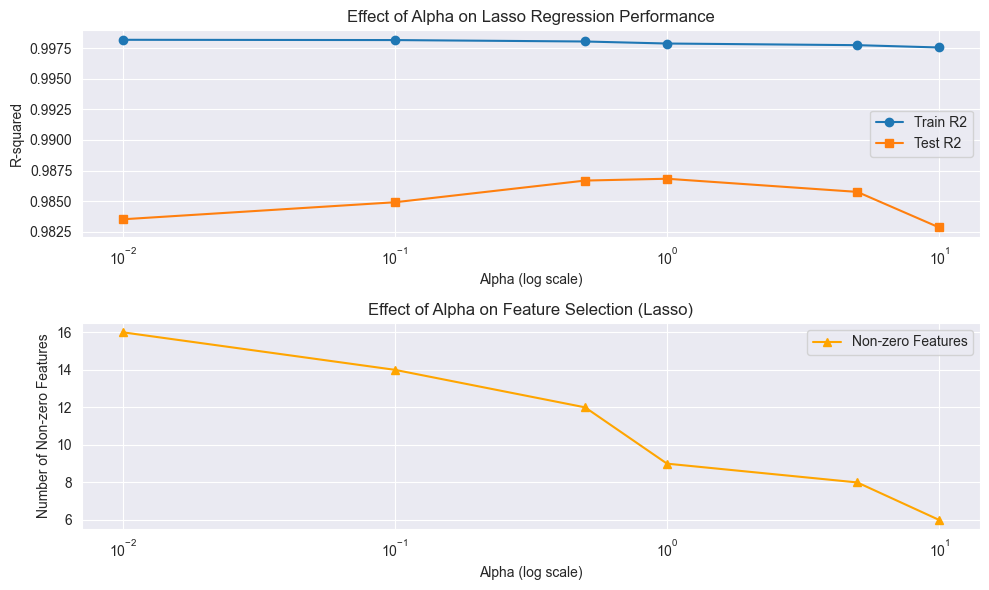

In [10]:
# Evaluate Lasso regression for different alpha values
alphas_lasso = [0.01, 0.1, 0.5, 1, 5, 10]
r2_train_lasso_scores = []
r2_test_lasso_scores = []
non_zero_features = []

for alpha in alphas_lasso:
    lasso = Lasso(alpha=alpha, max_iter=10000).fit(X_train, y_train)
    r2_train_lasso_scores.append(lasso.score(X_train, y_train))
    r2_test_lasso_scores.append(lasso.score(X_test, y_test))
    non_zero_features.append(np.sum(lasso.coef_ != 0))

# Plot R-squared scores for training and test sets and non-zero features
plt.figure(figsize=(10, 6))

# R-squared scores
plt.subplot(2, 1, 1)
plt.plot(alphas_lasso, r2_train_lasso_scores, marker='o', label='Train R2')
plt.plot(alphas_lasso, r2_test_lasso_scores, marker='s', label='Test R2')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('R-squared')
plt.title('Effect of Alpha on Lasso Regression Performance')
plt.legend()
plt.grid(True)

# Non-zero features
plt.subplot(2, 1, 2)
plt.plot(alphas_lasso, non_zero_features, marker='^', color='orange', label='Non-zero Features')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Number of Non-zero Features')
plt.title('Effect of Alpha on Feature Selection (Lasso)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

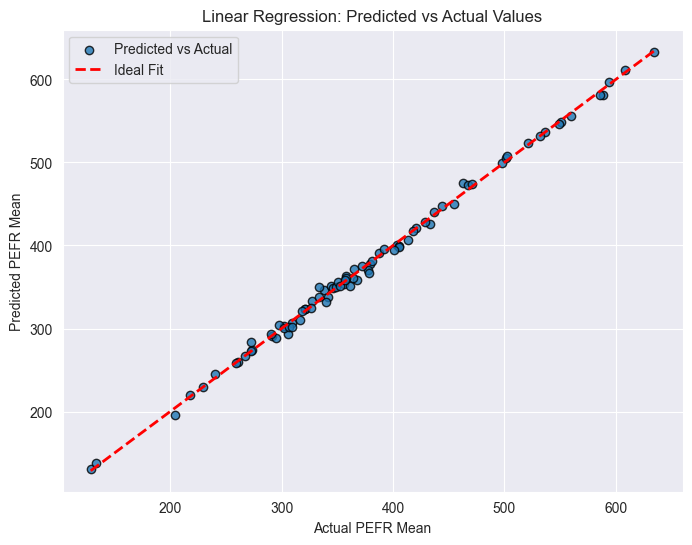

In [12]:
# Re-importing necessary libraries and loading the dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Reload the dataset
file_path = 'project_data/Merged_NonMissing_Patient_Data.csv'
patient_data = pd.read_csv(file_path)

# Define features and target variable
features = patient_data.drop(columns=['ID', 'pefr_mean'])
target = patient_data['pefr_mean']

# Train the Linear Regression model
linear_model = LinearRegression().fit(features, target)
predictions = linear_model.predict(features)

# Visualization of regression fit: predicted vs actual values
plt.figure(figsize=(8, 6))
plt.scatter(target, predictions, alpha=0.8, edgecolors='k', label='Predicted vs Actual')
plt.plot([target.min(), target.max()], [target.min(), target.max()], 'r--', lw=2, label='Ideal Fit')

plt.xlabel('Actual PEFR Mean')
plt.ylabel('Predicted PEFR Mean')
plt.title('Linear Regression: Predicted vs Actual Values')
plt.legend()
plt.grid(True)
plt.show()

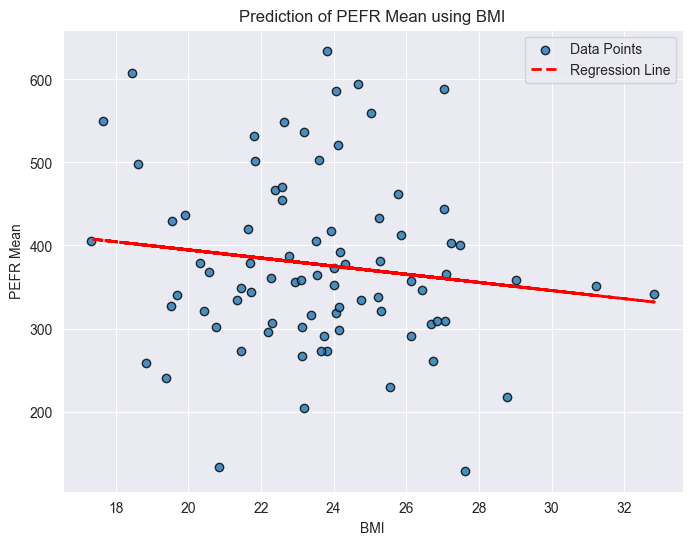

In [13]:
# Visualization: BMI vs PEFR Mean with regression line

# Extract BMI and target (PEFR Mean)
bmi = patient_data['BMI']
pefr_mean = patient_data['pefr_mean']

# Fit a simple linear regression model for BMI and PEFR Mean
bmi_model = LinearRegression().fit(bmi.values.reshape(-1, 1), pefr_mean)
bmi_pred = bmi_model.predict(bmi.values.reshape(-1, 1))

# Plotting
plt.figure(figsize=(8, 6))
plt.scatter(bmi, pefr_mean, alpha=0.8, edgecolors='k', label='Data Points')
plt.plot(bmi, bmi_pred, 'r--', lw=2, label='Regression Line')

plt.xlabel('BMI')
plt.ylabel('PEFR Mean')
plt.title('Prediction of PEFR Mean using BMI')
plt.legend()
plt.grid(True)
plt.show()

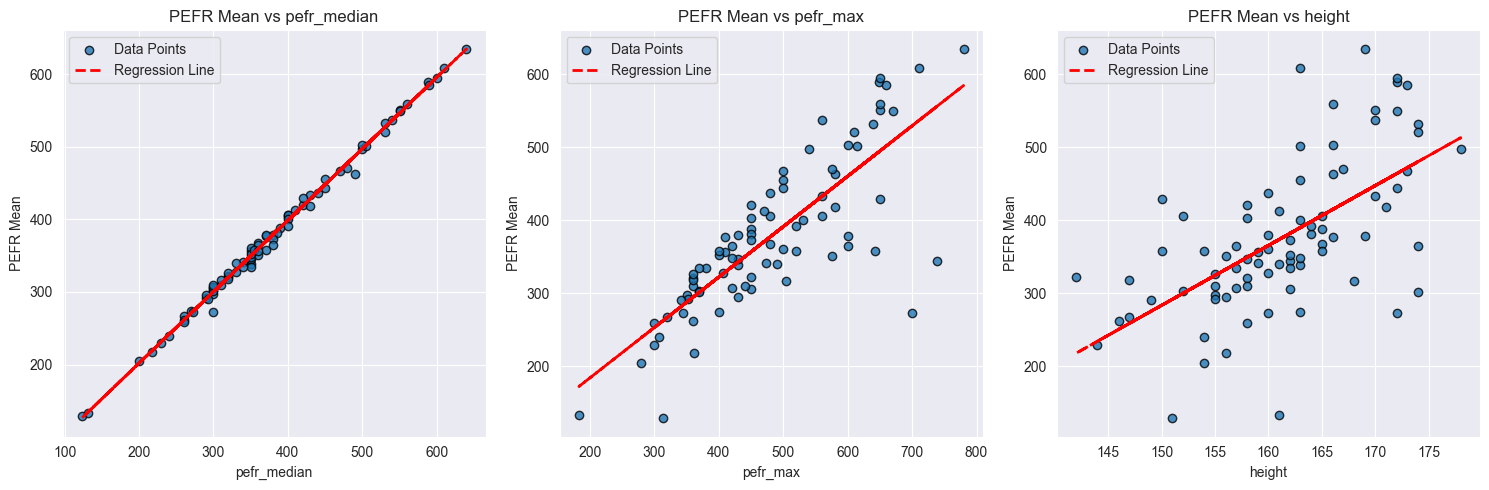

In [15]:
# Visualization: Scatter plots for top correlated features

# List of features to visualize
features_to_plot = ['pefr_median', 'pefr_max', 'height']

# Create scatter plots with regression lines
plt.figure(figsize=(15, 5))
for i, feature in enumerate(features_to_plot, 1):
    plt.subplot(1, 3, i)
    # Scatter plot
    plt.scatter(patient_data[feature], patient_data['pefr_mean'], alpha=0.8, edgecolors='k', label='Data Points')
    
    # Regression line
    model = LinearRegression().fit(patient_data[feature].values.reshape(-1, 1), patient_data['pefr_mean'])
    predicted = model.predict(patient_data[feature].values.reshape(-1, 1))
    plt.plot(patient_data[feature], predicted, 'r--', lw=2, label='Regression Line')
    
    plt.xlabel(feature)
    plt.ylabel('PEFR Mean')
    plt.title(f'PEFR Mean vs {feature}')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

In [7]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# Step 1: Load the data
data_file = 'project_data/Merged_NonMissing_Patient_Data.csv'
data = pd.read_csv(data_file)

# Step 2: Define the target and predictors
target = 'pefr_mean'  # Corrected target column name
predictors = [col for col in data.columns if col != target and col != 'ID']  # Exclude target and ID column

# Step 3: Prepare the data

X = data[predictors]

#(Dependent Variable/Target Variable):
y = data[target]

# Step 4: Train a regression model
model = LinearRegression()
model.fit(X, y)

# Step 5: Extract coefficients and format the regression equation
coefficients = model.coef_
intercept = model.intercept_

# Build the regression equation
regression_equation = f"y = {intercept:.2f} "
for i, coef in enumerate(coefficients):
    regression_equation += f"+ ({coef:.2f}) * {predictors[i]} "

# Display the regression equation
print("\nRegression Equation:")
print(regression_equation)

# Save it to a text file
output_file = 'project_data/regression_equation.txt'
with open(output_file, 'w') as f:
    f.write(regression_equation)

print(f"\nRegression equation saved to: {output_file}")


Regression Equation:
y = -8.36 + (-0.00) * age + (-1.22) * sex + (-0.11) * smoke + (0.06) * smoke_amount + (0.27) * height + (-0.28) * weight + (0.84) * BMI + (-14.10) * BSA + (1.04) * exposure + (-0.26) * region + (-0.01) * pefr_count + (-0.01) * pefr_min + (0.97) * pefr_median + (0.02) * pefr_max + (0.00) * pefr_sum + (-0.27) * pefr_std + (1.31) * pefr_skew 

Regression equation saved to: project_data/regression_equation.txt


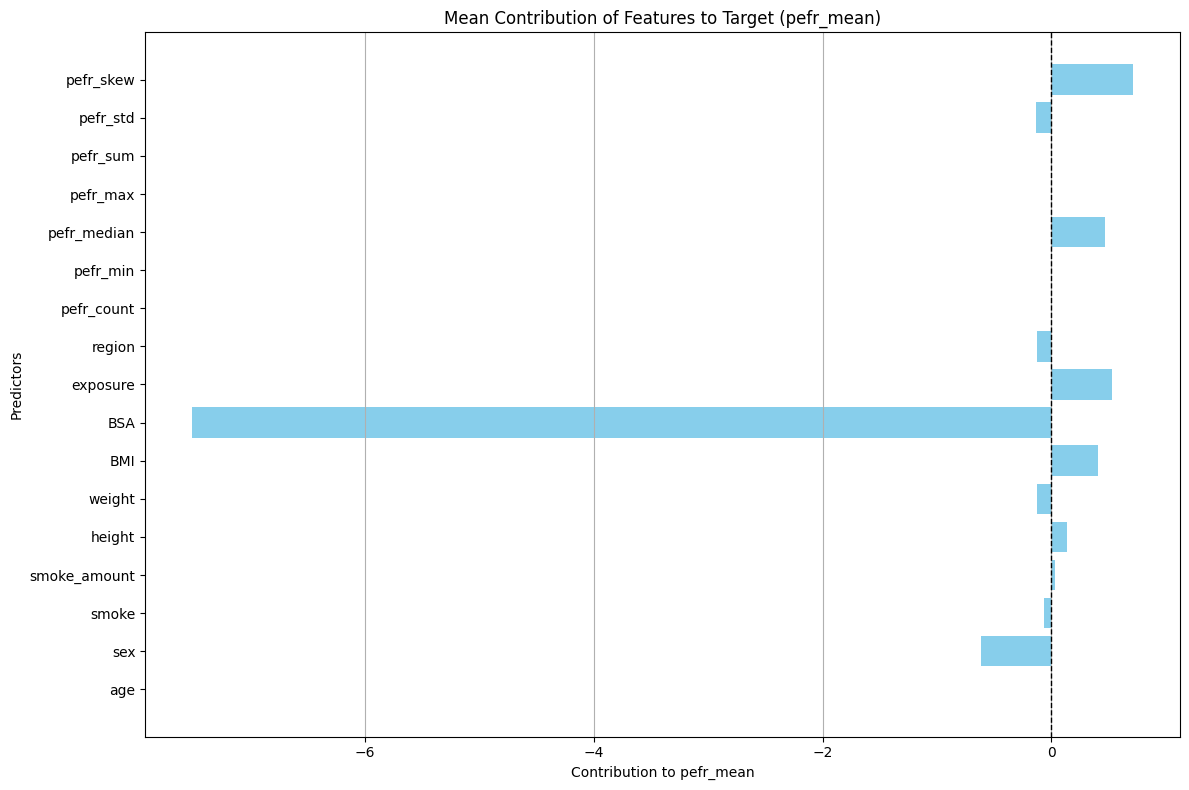

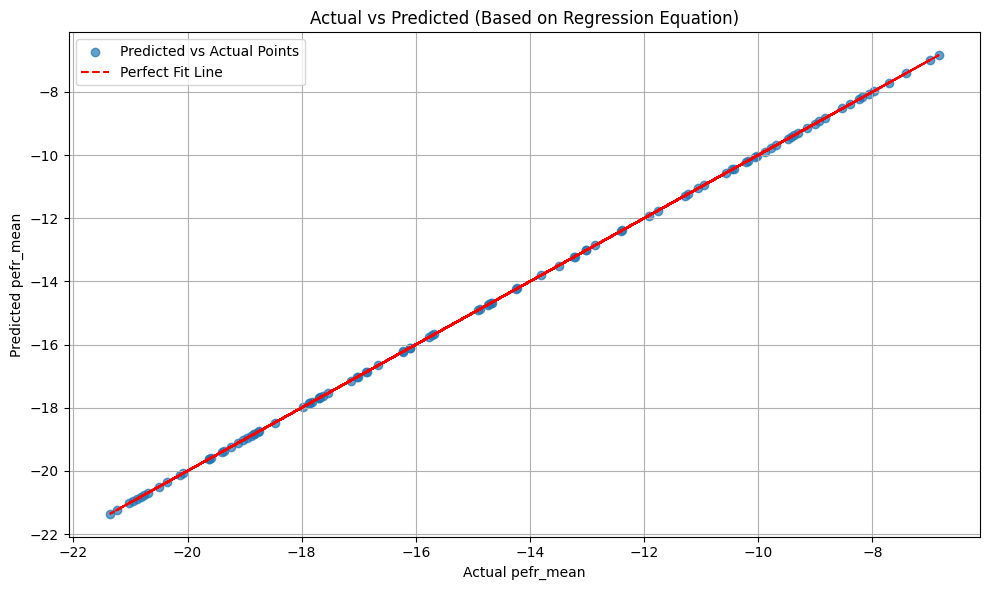

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Regression coefficients and intercept from your equation
coefficients = np.array([
    -0.00, -1.22, -0.11, 0.06, 0.27, -0.28, 0.84, -14.10, 1.04, -0.26,
    -0.01, -0.01, 0.97, 0.02, 0.00, -0.27, 1.31
])
intercept = -8.36
predictors = [
    'age', 'sex', 'smoke', 'smoke_amount', 'height', 'weight', 'BMI',
    'BSA', 'exposure', 'region', 'pefr_count', 'pefr_min', 'pefr_median',
    'pefr_max', 'pefr_sum', 'pefr_std', 'pefr_skew'
]

# Simulating some random data for visualization
np.random.seed(42)
simulated_X = np.random.rand(100, len(predictors))  # 100 rows, 17 predictors
simulated_y_actual = intercept + np.dot(simulated_X, coefficients)  # Actual y values
simulated_y_predicted = simulated_y_actual  # Predicted (same here for visualization simplicity)

# Contribution Calculation
contributions = simulated_X * coefficients  # Each feature's contribution to y
mean_contributions = contributions.mean(axis=0)  # Mean contribution per predictor

# 1. Visualize Mean Contributions of Features
plt.figure(figsize=(12, 8))
plt.barh(predictors, mean_contributions, color='skyblue')
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title("Mean Contribution of Features to Target (pefr_mean)")
plt.xlabel("Contribution to pefr_mean")
plt.ylabel("Predictors")
plt.grid(axis='x')
plt.tight_layout()
plt.show()

# 2. Visualize Actual vs Predicted Scatter Plot
plt.figure(figsize=(10, 6))
plt.scatter(simulated_y_actual, simulated_y_predicted, alpha=0.7, label="Predicted vs Actual Points")
plt.plot(simulated_y_actual, simulated_y_actual, color='red', linestyle='--', label="Perfect Fit Line")
plt.title("Actual vs Predicted (Based on Regression Equation)")
plt.xlabel("Actual pefr_mean")
plt.ylabel("Predicted pefr_mean")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()